In [1]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import pickle
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, classification_report

In [2]:
class ThreatDetector(nn.Module):
    def __init__(self, input_dim):
        super(ThreatDetector, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.network(x)

# Load original model and scaler
device = torch.device("cpu")
model = ThreatDetector(input_dim=78)
model.load_state_dict(torch.load("../results/threat_detector.pth", map_location=device))
model.eval()

with open("../results/scaler.pkl", "rb") as f:
    scaler = pickle.load(f)

print("Loaded original model and scaler")

Loaded original model and scaler


## Prepare Data

In [3]:
# Load the exact split from threat_detection.ipynb (same held-out test set as the original model)
split = np.load("../results/data_split.npz")
X_train, y_train = split["X_train"], split["y_train"]
X_test, y_test = split["X_test"], split["y_test"]

print(f"Train: {X_train.shape} | Test: {X_test.shape}")

Train: (566498, 78) | Test: (157361, 78)


## PGD attack

In [4]:
"""
PGD Attack - iterative version of FGSM
epsilon = total allowed perturbation budget
alpha = step size per iteration
num_steps = how many iterations

PGD with margin loss - works better when model is higly confident. 
Instead of CrossEntropy, we directly maximize (logit_benign - logit_attack)
It directly pushes the model toward predicting benign
"""
def pgd_attack(model, X, epsilon, alpha=0.01, num_steps=40):
    X_tensor = torch.tensor(X, dtype=torch.float32)
    X_adv = X_tensor.clone()

    for step in range(num_steps):
        X_adv.requires_grad_(True)

        output = model(X_adv)
        # Margin loss: maximize gap between benign logit and attack logit
        loss = (output[:, 0] - output[:, 1]).mean()
        loss.backward()

        # Small step in gradient direction
        X_adv = X_adv + alpha * X_adv.grad.sign()

        # Project back within epsilon ball - keeps perturbation bounded
        X_adv = torch.clamp(X_adv, X_tensor - epsilon, X_tensor + epsilon)
        X_adv = X_adv.detach()

    return X_adv.numpy()

print("PGD function defined")    # for confirmation

PGD function defined


## Adversarial Training

In [5]:
"""
Adversarial Training - for each training batch:
- Take a batch of clean training data
- Generate PGD adversarial examples from it on the fly
- Mix clean and adversarial example together
- Train on the combined batch

adv_ratio - is the fraction of each batch replaced with adversarial examples
0.5 - means half clean, half adversarial
"""
def adversarial_train(model, X_train, y_train, epochs=10, batch_size=512, lr=1e-3, epsilon=0.1, adv_ratio=0.5):
    model.train()

    class_counts = np.bincount(y_train)
    weights = torch.tensor(1.0 / class_counts, dtype=torch.float32)
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_ds = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train, dtype=torch.long)
    )
    loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

    for epoch in range(1, epochs + 1):
        total_loss = 0.0

        for X_batch, y_batch in loader:
            # Split batch: (1 - adv_ratio) clean, adv_ratio adversarial
            split = int(len(X_batch) * (1 - adv_ratio))
            X_clean, X_to_attack = X_batch[:split], X_batch[split:]
            y_clean, y_to_attack = y_batch[:split], y_batch[split:]

            # Only perturb malicious rows - pushing benign rows toward "benign" teaches nothing
            X_adv = X_to_attack.clone()
            is_attack = y_to_attack == 1
            if is_attack.any():
                model.eval()
                X_adv[is_attack] = torch.tensor(
                    pgd_attack(model, X_to_attack[is_attack].numpy(), epsilon=epsilon, num_steps=10))
                model.train()

            # Combining clean + adversarial
            X_combined = torch.cat([X_clean, X_adv])
            y_combined = torch.cat([y_clean, y_to_attack])

            optimizer.zero_grad()
            loss = criterion(model(X_combined), y_combined)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        print(f"Epoch {epoch:02d}/{epochs} | Loss: {total_loss/len(loader):.4f}")

    model.eval()    # switch off dropout / batch-stat BatchNorm before anyone evaluates it
    return model
print("Adversarial training function defined")

Adversarial training function defined


## Hardened Model

In [6]:
# Fresh model
hardened_model = ThreatDetector(input_dim=78).to(device)

print("Starting Adversarial Training...")
print("(This will take several minutes - each batch generate PGD examples)\n")

hardened_model = adversarial_train(
    hardened_model,
    X_train, y_train,
    epochs=10,
    batch_size=512,
    epsilon=0.1,
    adv_ratio=0.5
)

print("\nAdversarial Training Complete!")

Starting Adversarial Training...
(This will take several minutes - each batch generate PGD examples)

Epoch 01/10 | Loss: 0.1363
Epoch 02/10 | Loss: 0.1026
Epoch 03/10 | Loss: 0.0957
Epoch 04/10 | Loss: 0.0916
Epoch 05/10 | Loss: 0.0891
Epoch 06/10 | Loss: 0.0857
Epoch 07/10 | Loss: 0.0837
Epoch 08/10 | Loss: 0.0825
Epoch 09/10 | Loss: 0.0815
Epoch 10/10 | Loss: 0.0801

Adversarial Training Complete!


## Original vs Hardened Model

In [7]:
def eval_under_attack(model, X_test, y_test, epsilon=0.1):
    model.eval()
    # Run PGD attack then measure accuracy
    # Only attack the attack examples
    attack_mask = y_test == 1
    X_attacks = X_test[attack_mask]
    y_attacks = y_test[attack_mask]

    X_adv = pgd_attack(model, X_attacks, epsilon=epsilon, num_steps=40)

    adv_tensor = torch.tensor(X_adv, dtype=torch.float32)
    loader = DataLoader(TensorDataset(adv_tensor), batch_size=1024)

    preds = []
    with torch.no_grad():
        for(X_batch,) in loader:
            out = model(X_batch)
            preds.extend(out.argmax(1).numpy())

    acc = (np.array(preds) == y_attacks).mean()
    return acc

epsilons = [0.01, 0.05, 0.1, 0.2, 0.3]

print("Benchmarking both models under PGD attack... \n")

original_accs = []
hardened_accs = []

for eps in epsilons:
    print(f"Testing epsilon={eps:.2f}...")
    orig_acc = eval_under_attack(model, X_test, y_test, epsilon=eps)
    hard_acc = eval_under_attack(hardened_model, X_test, y_test, epsilon=eps)
    original_accs.append(orig_acc)
    hardened_accs.append(hard_acc)
    print(f"Original: {orig_acc:.1%} | Hardened: {hard_acc:.1%}")

Benchmarking both models under PGD attack... 

Testing epsilon=0.01...
Original: 95.9% | Hardened: 99.5%
Testing epsilon=0.05...
Original: 68.1% | Hardened: 99.4%
Testing epsilon=0.10...
Original: 54.5% | Hardened: 99.0%
Testing epsilon=0.20...
Original: 40.6% | Hardened: 84.0%
Testing epsilon=0.30...
Original: 26.5% | Hardened: 75.1%


## Fine-Tune Original Model

In [8]:
import copy

hardened_model2 = ThreatDetector(input_dim=78)
hardened_model2.load_state_dict(torch.load("../results/threat_detector.pth", map_location=device))     # starting from already-trained model

print("Fine-tuning from orginal model weights...")
print("(adv_ratio=0.3, lr=1e-4 (less aggressive than before))\n")

hardened_model2 = adversarial_train(
    hardened_model2,
    X_train, y_train,
    epochs=10,
    batch_size=512,
    lr=1e-4,                  # lower learning rate - preserve exisitng knowledge
    epsilon=0.1,
    adv_ratio=0.3             # less adversarial - 30% instead of 50%
)

print("\nFine-Tuning Complete!")

Fine-tuning from orginal model weights...
(adv_ratio=0.3, lr=1e-4 (less aggressive than before))

Epoch 01/10 | Loss: 0.1312
Epoch 02/10 | Loss: 0.0953
Epoch 03/10 | Loss: 0.0903
Epoch 04/10 | Loss: 0.0867
Epoch 05/10 | Loss: 0.0841
Epoch 06/10 | Loss: 0.0832
Epoch 07/10 | Loss: 0.0812
Epoch 08/10 | Loss: 0.0800
Epoch 09/10 | Loss: 0.0788
Epoch 10/10 | Loss: 0.0780

Fine-Tuning Complete!


## Checking Clean Accuracy

In [9]:
def evaluate_clean(model, X, y):
    model.eval()
    with torch.no_grad():
        preds = model(torch.tensor(X, dtype=torch.float32)).argmax(1).numpy()
    acc = (preds == y).mean()
    fpr = (preds[y == 0] == 1).mean()    # benign flows wrongly flagged as attacks
    print(f"  Overall accuracy:     {acc:.1%}")
    print(f"  False positive rate:  {fpr:.1%}")
    print(classification_report(y, preds, target_names=["Benign", "Attack"], digits=4))
    return acc

print("Original model (clean data):")
orig_clean_acc = evaluate_clean(model, X_test, y_test)

print("\nHardened model 1 - from scratch (clean data):")
evaluate_clean(hardened_model, X_test, y_test)

print("\nHardened model 2 - fine-tuned (clean data):")
hard_clean_acc = evaluate_clean(hardened_model2, X_test, y_test)

Original model (clean data):
  Overall accuracy:     97.0%
  False positive rate:  3.5%
              precision    recall  f1-score   support

      Benign     0.9983    0.9655    0.9816    129594
      Attack     0.8604    0.9921    0.9216     27767

    accuracy                         0.9702    157361
   macro avg     0.9293    0.9788    0.9516    157361
weighted avg     0.9739    0.9702    0.9710    157361


Hardened model 1 - from scratch (clean data):
  Overall accuracy:     94.9%
  False positive rate:  6.1%
              precision    recall  f1-score   support

      Benign     0.9991    0.9393    0.9683    129594
      Attack     0.7786    0.9961    0.8740     27767

    accuracy                         0.9493    157361
   macro avg     0.8889    0.9677    0.9212    157361
weighted avg     0.9602    0.9493    0.9517    157361


Hardened model 2 - fine-tuned (clean data):
  Overall accuracy:     96.3%
  False positive rate:  4.4%
              precision    recall  f1-score   su

## Benchmarking under PGD attack

In [10]:
print("Benchmarking original vs fine-tuned model under PGD attack...\n")

original_accs  = []
hardened_accs  = []

for eps in epsilons:
    print(f"Testing epsilon={eps:.2f}...")
    orig_acc = eval_under_attack(model, X_test, y_test, epsilon=eps)
    hard_acc = eval_under_attack(hardened_model2, X_test, y_test, epsilon=eps)
    original_accs.append(orig_acc)
    hardened_accs.append(hard_acc)
    print(f"  Original: {orig_acc:.1%} | Hardened: {hard_acc:.1%}")

Benchmarking original vs fine-tuned model under PGD attack...

Testing epsilon=0.01...
  Original: 95.9% | Hardened: 98.9%
Testing epsilon=0.05...
  Original: 68.1% | Hardened: 95.1%
Testing epsilon=0.10...
  Original: 54.5% | Hardened: 88.8%
Testing epsilon=0.20...
  Original: 40.6% | Hardened: 71.8%
Testing epsilon=0.30...
  Original: 26.5% | Hardened: 61.7%


## Final Comparison Plot

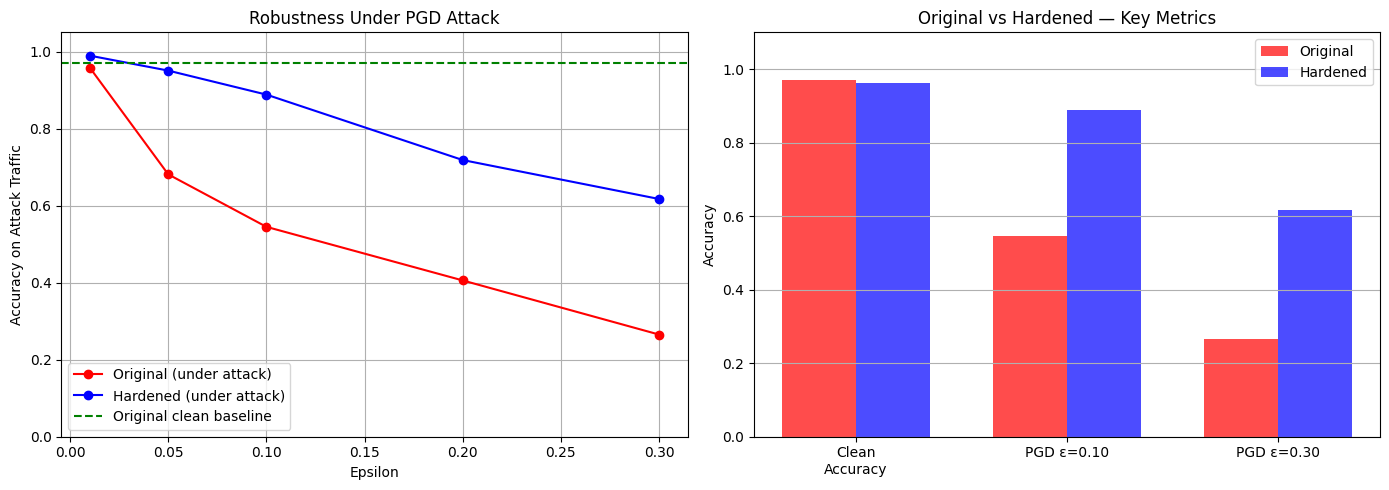


Final Summary:
Clean accuracy:    Original 97.0% → Hardened 96.3% (-0.7%)
PGD ε=0.10:        Original 54.5% → Hardened 88.8% (+34.3%)
PGD ε=0.30:        Original 26.5% → Hardened 61.7% (+35.2%)


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: under attack
axes[0].plot(epsilons, original_accs,  marker='o', color='red',   label='Original (under attack)')
axes[0].plot(epsilons, hardened_accs,  marker='o', color='blue',  label='Hardened (under attack)')
axes[0].axhline(y=orig_clean_acc, color='green', linestyle='--', label='Original clean baseline')
axes[0].set_title("Robustness Under PGD Attack")
axes[0].set_xlabel("Epsilon")
axes[0].set_ylabel("Accuracy on Attack Traffic")
axes[0].set_ylim(0, 1.05)
axes[0].legend()
axes[0].grid(True)

# Right: clean vs adversarial tradeoff summary
categories = ['Clean\nAccuracy', 'PGD ε=0.10', 'PGD ε=0.30']
# epsilons[2] = 0.10, epsilons[4] = 0.30
orig_vals   = [orig_clean_acc, original_accs[2], original_accs[4]]
hard_vals   = [hard_clean_acc, hardened_accs[2], hardened_accs[4]]

x = np.arange(len(categories))
width = 0.35
axes[1].bar(x - width/2, orig_vals, width, label='Original', color='red',  alpha=0.7)
axes[1].bar(x + width/2, hard_vals, width, label='Hardened', color='blue', alpha=0.7)
axes[1].set_title("Original vs Hardened — Key Metrics")
axes[1].set_ylabel("Accuracy")
axes[1].set_ylim(0, 1.1)
axes[1].set_xticks(x)
axes[1].set_xticklabels(categories)
axes[1].legend()
axes[1].grid(True, axis='y')

plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/defense_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

print("\nFinal Summary:")
print(f"Clean accuracy:    Original {orig_clean_acc:.1%} → Hardened {hard_clean_acc:.1%} ({hard_clean_acc - orig_clean_acc:+.1%})")
print(f"PGD ε=0.10:        Original {original_accs[2]:.1%} → Hardened {hardened_accs[2]:.1%} (+{hardened_accs[2]-original_accs[2]:.1%})")
print(f"PGD ε=0.30:        Original {original_accs[4]:.1%} → Hardened {hardened_accs[4]:.1%} (+{hardened_accs[4]-original_accs[4]:.1%})")

## Save Hardened Model

In [12]:
torch.save(hardened_model2.state_dict(), "../results/hardened_threat_detector.pth")
print("Hardened model saved in results/hardened_threat_detector.pth")

Hardened model saved in results/hardened_threat_detector.pth
